# 🧹 Limpieza de datos

Notebook interactivo para explorar, limpiar y exportar los datos.
Al final, los datos limpios se guardan en `data/processed/datos_limpios.csv`
para ser consumidos por el dashboard.

In [1]:
# Ajuste de ruta para importar desde src/
import sys
from difflib import SequenceMatcher
from pathlib import Path
from nltk.stem import SnowballStemmer
sys.path.insert(0, str(Path("..").resolve()))

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option('display.max_colwidth', None)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
stemmer = SnowballStemmer('spanish')

## 1. Cargar datos crudos

In [2]:
try:
  df = pd.read_csv(RAW_CSV)
except:
  import requests

  SHEET_CSV_URL = "https://docs.google.com/spreadsheets/d/e/2PACX-1vQmx6xTqJDv0c-e9SAWH7Jku6ZCiIfIbSrKHHXD1oxrslbA0j3ZqpAP6pP8SXd2CmLB5WDHanazOy12/pub?gid=1639119631&single=true&output=csv"

  response = requests.get(SHEET_CSV_URL)
  with open('datos_raw.csv', 'wb') as f:
      f.write(response.content)

  df = pd.read_csv('datos_raw.csv')
print(f"Shape original: {df.shape}")
df.head()

Shape original: (20, 21)


,Marca temporal,Dirección de correo electrónico,¿Deseas participar en el estudio?,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
0,12/10/2026 16:26:08,321184074@pcpuma.acatlan.unam.mx,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,30/10/2026 18:40:27,321188065@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,7.0,Si,14.0,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",+/- 2 años,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pasado y comiendo algo.,Un viaje a otro país.,Cómo si fuera la primera vez
2,30/10/2026 18:55:47,424059594@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,7.0,No,12.0,Que una persona te genere muchas emociones y no dejes de pensar en ella,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa persona,"Leal, respetuosa, cariñosa y con buen sentido del humor",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriores y que tome un papel exageradamente toxico,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar para esa persona cuando lo necesita",Escucharme hablar del mismo tema infinidad de veces,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después una cena en un lago o algo asi,La canción Mi Riqueza
3,30/10/2026 23:58:24,423085822@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,MAC,7.0,Si,15.0,Escuche Amar y querer de José José para más detalles.,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus zapatos.",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empatía.,"El que violente física, emocionalmente de mi. Aislamiento, Love bombing.",+/- 3 años,"Tener retroalimentación, pasar un rato juntos, dedicarle de mi tiempo ya sea dándoles algo o brindarles algo que me nazca.","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jugando, etc., llegar una solución y que ambos estén de acuerdo.","Simplemente estar con esa persona lo hace ideal, además de que lo mejor siempre sale de imprevisto.","Something About You de Eyedress y Dent May, recomendadísima."
4,31/10/2026 13:10:25,424000455@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,MAC,7.0,No,12.0,Que te atraiga la persona y que la acept

## 2. Exploración inicial

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 21 columns):
 #   Column                                                                                Non-Null Count  Dtype  
---  ------                                                                                --------------  -----  
 0   Marca temporal                                                                        20 non-null     object 
 1   Dirección de correo electrónico                                                       20 non-null     object 
 2   ¿Deseas participar en el estudio?                                                     20 non-null     object 
 3   ¿A qué área de conocimiento pertenece tu carrera?                                     19 non-null     object 
 4   ¿Cuál es tu carrera?                                                                  19 non-null     object 
 5   ¿En qué semestre te encuentras actualmente?                                           1

In [4]:
# Seleccionamos la columna de quién desea participar y la de tiempo
col_participar = df.columns[2]
col_tiempo = df.columns[0]

# Mapear "Sí" → 1, "No" → 0
df[col_participar] = df[col_participar].map({"Sí": 1, "No": 0})
df = df[df[col_participar] == 1].copy()

# Eliminar columnas innecesarias
df = df.drop(columns=[col_participar, col_tiempo])

In [5]:
# Extraer números de cuenta
df = df.rename(columns={df.columns[0]: "No. Cuenta"})
col_cuenta = df.columns[0]
df[col_cuenta] = df[col_cuenta].astype(str).str.extract(r'(\d{9})')

In [6]:
display(df.describe(include='all'))

,No. Cuenta,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
count,19,19,19,19.0,19,19.000000,19,19,19,19,19,19,19,19,19,19,19,19,19
unique,19,1,11,NaN,4,NaN,19,19,19,19,19,19,19,16,19,19,18,19,19
top,321188065,Área 1: Ciencias Físico-Matemáticas y de las Ingenierías,Matemáticas Aplicadas y Computación,NaN,No,NaN,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",3 años de diferencia,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablarlo,Un viaje a otro país.,Cómo si fuera la primera vez
freq,1,19,4,NaN,9,NaN,1,1,1,1,1,1,1,2,1,1,2,1,1
mean,NaN,NaN,NaN,7.0,NaN,12.684211,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,0.0,NaN,6.280947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,7.0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,7.0,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,7.0,NaN,14.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,7.0,NaN,16.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Eliminando la columna del área de conocimiento (todos son de la 1)
# Eliminando la columna del semestre, todos son de 7mo
df = df.drop(columns=[df.columns[1], df.columns[3]])

In [8]:
# Exploración de columnas
display(df.head(10))
df.dtypes

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,Matemáticas Aplicadas y Computación,Si,14.0,Es un sentimiento dirigido hacia otra persona con la cuál es de tu agrado hacer cualquier cosa e incluso con quién deseas pasar toda la vida.,Honestidad y confianza,No lastimar física o emocionalmente a la otra parte.,"El apoyo, porque me hace sentir especial e importante, escuchado y feliz.",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de controlar todo.","Frases para controlar o atacar emocionalmente a alguien.\nQuerer estar 24/7 con la otra persona.\nDependencia emocional.\nNo entender un ""No"".",+/- 2 años,Querer estar cerca de la otra persona.\nDarle de comer.\nHacer tiempo para estar juntos.,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pasado y comiendo algo.,Un viaje a otro país.,Cómo si fuera la primera vez
2,424059594,Matemáticas Aplicadas y Computación,No,12.0,Que una persona te genere muchas emociones y no dejes de pensar en ella,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa persona,"Leal, respetuosa, cariñosa y con buen sentido del humor",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriores y que tome un papel exageradamente toxico,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar para esa persona cuando lo necesita",Escucharme hablar del mismo tema infinidad de veces,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después una cena en un lago o algo asi,La canción Mi Riqueza
3,423085822,MAC,Si,15.0,Escuche Amar y querer de José José para más detalles.,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus zapatos.",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empatía.,"El que violente física, emocionalmente de mi. Aislamiento, Love bombing.",+/- 3 años,"Tener retroalimentación, pasar un rato juntos, dedicarle de mi tiempo ya sea dándoles algo o brindarles algo que me nazca.","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jugando, etc., llegar una solución y que ambos estén de acuerdo.","Simplemente estar con esa persona lo hace ideal, además de que lo mejor siempre sale de imprevisto.","Something About You de Eyedress y Dent May, recomendadísima."
4,424000455,MAC,No,12.0,Que te atraiga la persona y que la aceptes como es,Honestidad,Que respete mis límites,Empatía,Alto,Que sea mentiroso que sea indeciso,Controlador que sea grosero,2 años más que yo,Detalles tiempo de calidad,Sorprenderme en mi cumpleaños,Hablarlo,Una cita romántica,Love Rosie
5,424144407,Matemáticas aplicadas y Computación,Si,13.0,"Para mí estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegría, cariño, y amor.","Comunicación, respeto y sinceridad","Simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educación y valores","El ser escuchado, la atención a los detalles me hace sentir que valgo","Basándome en mi pareja y patrones que he tenido 

,0
No. Cuenta,object
¿Cuál es tu carrera?,object
¿Tienes pareja actualmente?,object
¿A qué edad fue tu primera relación amorosa?,float64
¿Qué significa para ti estar enamorado?,object
¿Cuál consideras que es la base de la confianza?,object
¿Cómo defines el respeto dentro de una relación?,object
¿Qué cualidad valoras más en una pareja y por qué?,object
Describe físicamente a tu pareja ideal,object
"¿Cuáles son tus ""no negociables"" en una relación?",object


In [9]:
nulos = df.isnull().sum()
display(nulos[nulos > 0] if nulos.sum() > 0 else "✅ No hay valores nulos en el dataset.")

'✅ No hay valores nulos en el dataset.'

## Funciones

In [10]:
def normalizar_texto(serie):
    # Convertir a string y minúsculas
    s = serie.astype(str).str.lower()

    # Quitar acentos y diéresis
    s = s.str.replace('á', 'a', regex=False)\
           .str.replace('é', 'e', regex=False)\
           .str.replace('í', 'i', regex=False)\
           .str.replace('ó', 'o', regex=False)\
           .str.replace('ú', 'u', regex=False)\
           .str.replace('ü', 'u', regex=False)\
           .str.replace('ñ', 'n', regex=False)

    # Quitar puntos
    s = s.str.replace(r'\.', '', regex=True)

    # Reemplazar múltiples espacios por uno solo y quitar espacios al inicio/final
    s = s.str.replace(r'\s+', ' ', regex=True).str.strip()

    # Si el valor era originalmente un NaN, devolverlo como NaN real
    s = s.replace(['nan', 'nat', 'none'], pd.NA)
    return s

def normalizar_lista(serie):
    """
    Estandariza una columna de listas de texto.
    """
    s = serie.astype(str)

    # 1. Reemplazar " y " por coma
    s = s.str.replace(r'\s+y\s+', ', ', regex=True)

    # 2. Limpiar espacios alrededor de comas
    s = s.str.replace(r'\s*,\s*', ', ', regex=True)

    # 3. Quitar puntos
    s = s.str.replace(r'\.', '', regex=True)

    # 4. Quitar comas/espacios al inicio o final
    s = s.str.replace(r'^,\s*', '', regex=True)\
           .str.replace(r',\s*$', '', regex=True)\
           .str.strip()

    # 5. Manejar valores vacíos
    s = s.replace(['nan', 'nat', 'none', ''], pd.NA)

    return s

def mapear_carrera(texto, lista_oficial, umbral=0.75):
    """
    Compara un texto sucio contra una lista oficial y devuelve
    la coincidencia más alta si supera el umbral.
    """

    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan

    mejor_coincidencia = None
    max_similitud = 0.0

    # Comparar contra TODAS las carreras oficiales
    for carrera_oficial in lista_oficial:
        similitud = SequenceMatcher(None, texto, carrera_oficial.lower()).ratio()
        if similitud > max_similitud:
            max_similitud = similitud
            mejor_coincidencia = carrera_oficial

    # Si la mejor coincidencia supera el umbral, la asignamos
    if max_similitud >= umbral:
        return mejor_coincidencia
    else:
        # Si no llega al umbral, lo marcamos para revisión manual
        return texto

def limpiar_carrera(serie):
    """
    Limpia y unifica nombres de carreras
    """
    CARRERAS_OFICIALES = [
            "actuaria",
            "arquitectura",
            "ciencia de datos",
            "ingenieria civil",
            "matematicas aplicadas y computacion",
            "ciencias politicas y administracion publica",
            "comunicacion",
            "derecho",
            "economia",
            "relaciones internacionales",
            "sociologia",
            "diseño grafico",
            "filosofia",
            "pedagogia"
    ]
    # Trabajar sobre una copia
    s = serie.copy()

    # PASO 1: Quitar palabras clave y abreviaciones
    palabras_a_quitar = [
        r'\bingenier[ií]a\b', r'\bing\b', r'\bing\.\b',
        r'\blicenciatura\b', r'\blic\b', r'\blic\.\b',
        r'\blicenciatura en\b',
        r'\bcarrera\b', r'\buniversidad\b', r'\bunam\b',
        r'\bfacultad\b', r'\bfes\b'
    ]

    for patron in palabras_a_quitar:
        s = s.str.replace(patron, '', regex=True, case=False)

    # Limpiar espacios y comas sobrantes
    s = s.str.replace(r'\s*,\s*', ' ', regex=True)
    s = s.str.replace(r'\s+', ' ', regex=True)
    s = s.str.strip()

    mapeos_especificos = {
        'matematicas aplicadas y computacion': 'mac',
        'ingenieria civil': 'civil',
        'ciencias politicas y administracion publica': 'cpap',
        'relaciones internacionales': 'ri',
    }

    # PASO 3: Mapear a carreras oficiales usando .apply()
    s = s.apply(lambda x: mapear_carrera(x, CARRERAS_OFICIALES, umbral=0.90))
    for viejo, nuevo in mapeos_especificos.items():
            s = s.str.replace(viejo, nuevo, regex=False, case=False)

    return s

## Normalizar datos

In [11]:
# Normalizar columnas de texto
cols_a_normalizar = [col for i, col in enumerate(df.columns) if i not in [0, 3]]

for col in cols_a_normalizar:
    if df[col].dtype == 'str' or df[col].dtype == 'object':
        df[col] = normalizar_texto(df[col])
# Estandarizar columnas de lista
indices_listas = [5, 8, 9, 10, 12]
cols_listas = [df.columns[i] for i in indices_listas if i < len(df.columns)]

for col in cols_listas:
    df[col] = normalizar_lista(df[col])
display(df.head(10))

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,matematicas aplicadas y computacion,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de controlar todo","frases para controlar o atacar emocionalmente a alguien querer estar 24/7 con la otra persona dependencia emocional no entender un ""no""",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez
2,424059594,matematicas aplicadas y computacion,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, falta de respeto","que me hable mucho de sus relaciones anteriores, que tome un papel exageradamente toxico",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza
3,423085822,mac,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi aislamiento, love bombing",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima"
4,424000455,mac,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,matematicas aplicadas y computacion,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante

### Limpiando la columna de carrera

In [12]:
col_carrera = df.columns[1]
df[col_carrera] = limpiar_carrera(df[col_carrera])
display(df[col_carrera].value_counts().head(20))

df = df.drop(columns=[col_carrera])

,count
¿Cuál es tu carrera?,
mac,19


## Gráficos de frecuencia

In [13]:
display(df.head(10))

,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona con la cual es de tu agrado hacer cualquier cosa e incluso con quien deseas pasar toda la vida,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra parte,"el apoyo, porque me hace sentir especial e importante, escuchado y feliz",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de controlar todo","frases para controlar o atacar emocionalmente a alguien querer estar 24/7 con la otra persona dependencia emocional no entender un ""no""",+/- 2 anos,querer estar cerca de la otra persona darle de comer hacer tiempo para estar juntos,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pasado y comiendo algo,un viaje a otro pais,como si fuera la primera vez
2,424059594,no,12.0,que una persona te genere muchas emociones y no dejes de pensar en ella,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa persona,"leal, respetuosa, carinosa, con buen sentido del humor","infidelidad, falta de respeto","que me hable mucho de sus relaciones anteriores, que tome un papel exageradamente toxico",+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar para esa persona cuando lo necesita",escucharme hablar del mismo tema infinidad de veces,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues una cena en un lago o algo asi,la cancion mi riqueza
3,423085822,si,15.0,escuche amar y querer de jose jose para mas detalles,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus zapatos",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi aislamiento, love bombing",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos, dedicarle de mi tiempo ya sea dandoles algo o brindarles algo que me nazca","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jugando, etc, llegar una solucion y que ambos esten de acuerdo","simplemente estar con esa persona lo hace ideal, ademas de que lo mejor siempre sale de imprevisto","something about you de eyedress y dent may, recomendadisima"
4,424000455,no,12.0,que te atraiga la persona y que la aceptes como es,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,si,13.0,"para mi estar enamorado es querer compartir tu vida, tiempo y ciertos puntos importantes de ti con una persona que te gusta, te hace sentir paz, alegria, carino, y amor","comunicacion, respeto, sinceridad","simplemente tener tratos buenos ( exclusividad, sinceridad, lealtad) desde tu educacion y valores","el ser escuchado, la atencion a los detalles me hace sentir que valgo","basandome en mi pareja, patrones que he tenido los rasgos son, altos (170mts en adelante), complexion media, morenito","infidelidad, no tener tiempo de calidad","revisar el telefono, que le “caigan mal” mis amigos, el que qui

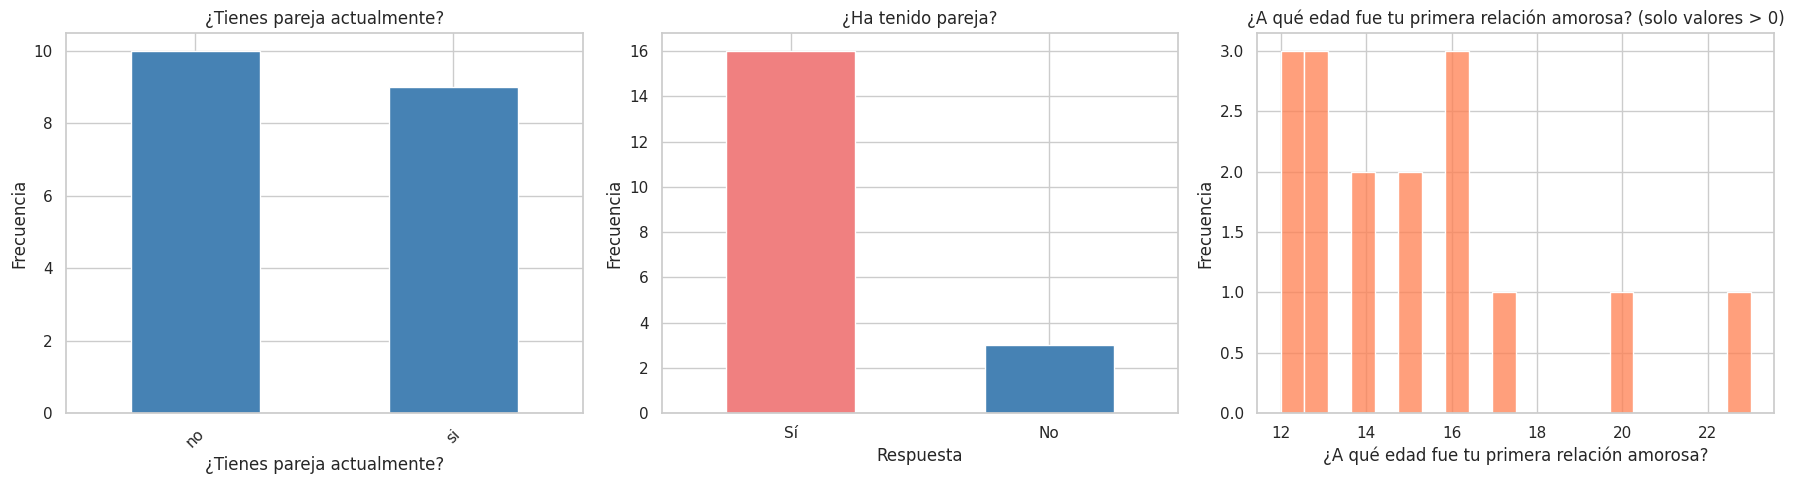

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Columna 1: Categórica (ha tenido pareja)
col_cat = df.columns[1]
counts = df[col_cat].value_counts()
counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title(f'{col_cat}')
axes[0].set_xlabel(col_cat)
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=45)

# Columna 2: Numérica (primera pareja)
col_pareja = df.columns[2]

# Función para mapear: 0 -> "No", cualquier otra cosa -> "Sí"
def clasificar_pareja(valor):
    if pd.isna(valor):
        return "No especificado"
    return "Sí" if valor != 0 else "No"

# Aplicar el mapeo y contar frecuencias
serie_pareja = df[col_pareja].apply(clasificar_pareja)
counts_pareja = serie_pareja.value_counts()

# Graficar (usamos colores distintos para Sí/No)
colores = {'Sí': 'lightcoral', 'No': 'steelblue', 'No especificado': 'gray'}
bar_colors = [colores.get(x, 'gray') for x in counts_pareja.index]

counts_pareja.plot(kind='bar', ax=axes[1], color=bar_colors)
axes[1].set_title(f'¿Ha tenido pareja?')
axes[1].set_xlabel('Respuesta')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=0)

# Columna 2: Numérica (edad) - Solo valores > 0
df_edad_filtrada = df[df[col_pareja] > 0][col_pareja]
sns.histplot(df_edad_filtrada, bins=20, ax=axes[2], color='coral')
axes[2].set_title(f'{col_pareja} (solo valores > 0)')
axes[2].set_xlabel(col_pareja)
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## Variables significativas

In [15]:
!pip install nltk

In [16]:
CONCEPTOS_ORIGINALES_BASE_CONFIANZA = [
    "honestidad", "confianza", "lealtad", "comunicacion",
    "vulnerable", "respeto", "sinceridad", "empatia",
    "apoyo", "comprension", "tiempo", "paciencia",
    "congruencia", "libertad", "amor", "transparencia", "responsabilidad"
]

CONCEPTOS_NO_NEGOCIABLES = [
    "honestidad", "mentira", "mentiras", "engano", "enganos", "mentiroso", "deshonestidad"
    "respeto", "falta de respeto", "maltrato",
    "lealtad", "fidelidad", "infidelidad", "traicion", "traicionar",
    "comunicacion", "silencio", "ignorar",
    "confianza", "desconfianza", "celos",
    "libertad", "espacio", "privacidad", "control", "posesividad", "asfixia",
    "empatia", "apoyo", "indiferencia", "manipulacion", "manipular",
    "tiempo", "proyecto_vida", "futuro", "hijos",
    "valores", "estabilidad", "madurez", "indeciso", "adiccion", "drogas",
    "humor", "inteligencia", "atraccion", "familia",
    "ayuda", "empatico", "respeto", "violencia"
]


In [17]:
CONCEPTOS_BASE_CONFIANZA = {
    stemmer.stem(palabra): palabra
    for palabra in CONCEPTOS_ORIGINALES_BASE_CONFIANZA
}
CONCEPTOS_NO_NEGOCIABLES = {
    stemmer.stem(palabra): palabra
    for palabra in CONCEPTOS_NO_NEGOCIABLES
}

In [18]:
def extraer_conceptos_clave(texto, CONCEPTOS_OBJETIVO):
    """
    Escanea el texto y solo devuelve las palabras que estén en nuestra lista objetivo.
    """
    palabras = re.findall(r'\b\w+\b', texto)
    palabras_stem = [stemmer.stem(p) for p in palabras]
    encontrados = []
    for raiz, palabra_original in CONCEPTOS_OBJETIVO.items():
        if raiz in palabras_stem :
            encontrados.append(palabra_original)

    if encontrados:
        return ", ".join(encontrados)
    else:
        return pd.NA

In [19]:
col_original = df.columns[4]

df[f"{col_original}"] = df[col_original].apply(
    lambda x: extraer_conceptos_clave(
        x if pd.notna(x) else "",
        CONCEPTOS_BASE_CONFIANZA
    )
)
display(display(df.iloc[:, [0, 4]].head(10)))

,No. Cuenta,¿Cuál consideras que es la base de la confianza?
1,321188065,"honestidad, confianza"
2,424059594,"honestidad, lealtad"
3,423085822,"comunicacion, vulnerable"
4,424000455,honestidad
5,424144407,"comunicacion, respeto, sinceridad"
6,321339968,"comunicacion, respeto"
7,424038010,"honestidad, confianza, respeto"
8,422032861,"honestidad, comunicacion"
9,424047638,"honestidad, comunicacion"
10,422085764,"honestidad, comunicacion"


None

In [23]:
col_original = df.columns[8]

df[f"{col_original}"] = df[col_original].apply(
    lambda x: extraer_conceptos_clave(
        x if pd.notna(x) else "",
        CONCEPTOS_NO_NEGOCIABLES
    )
)
display(display(df.iloc[:, [8, -1]].head(30)))

,"¿Cuáles son tus ""no negociables"" en una relación?","¿Cuáles son tus ""no negociables"" en una relación?_CONCEPTO"
1,"mentiras, enganos, infidelidad, control","mentiras, enganos, infidelidad, control"
2,"respeto, infidelidad","respeto, infidelidad"
3,"infidelidad, empatia, manipular","infidelidad, empatia, manipular"
4,"mentiras, indeciso","mentiras, indeciso"
5,"infidelidad, tiempo","infidelidad, tiempo"
6,"espacio, privacidad","espacio, privacidad"
7,adiccion,adiccion
8,"respeto, infidelidad","respeto, infidelidad"
9,"confianza, ayuda","confianza, ayuda"
10,"respeto, lealtad, confianza","respeto, lealtad, confianza"


None

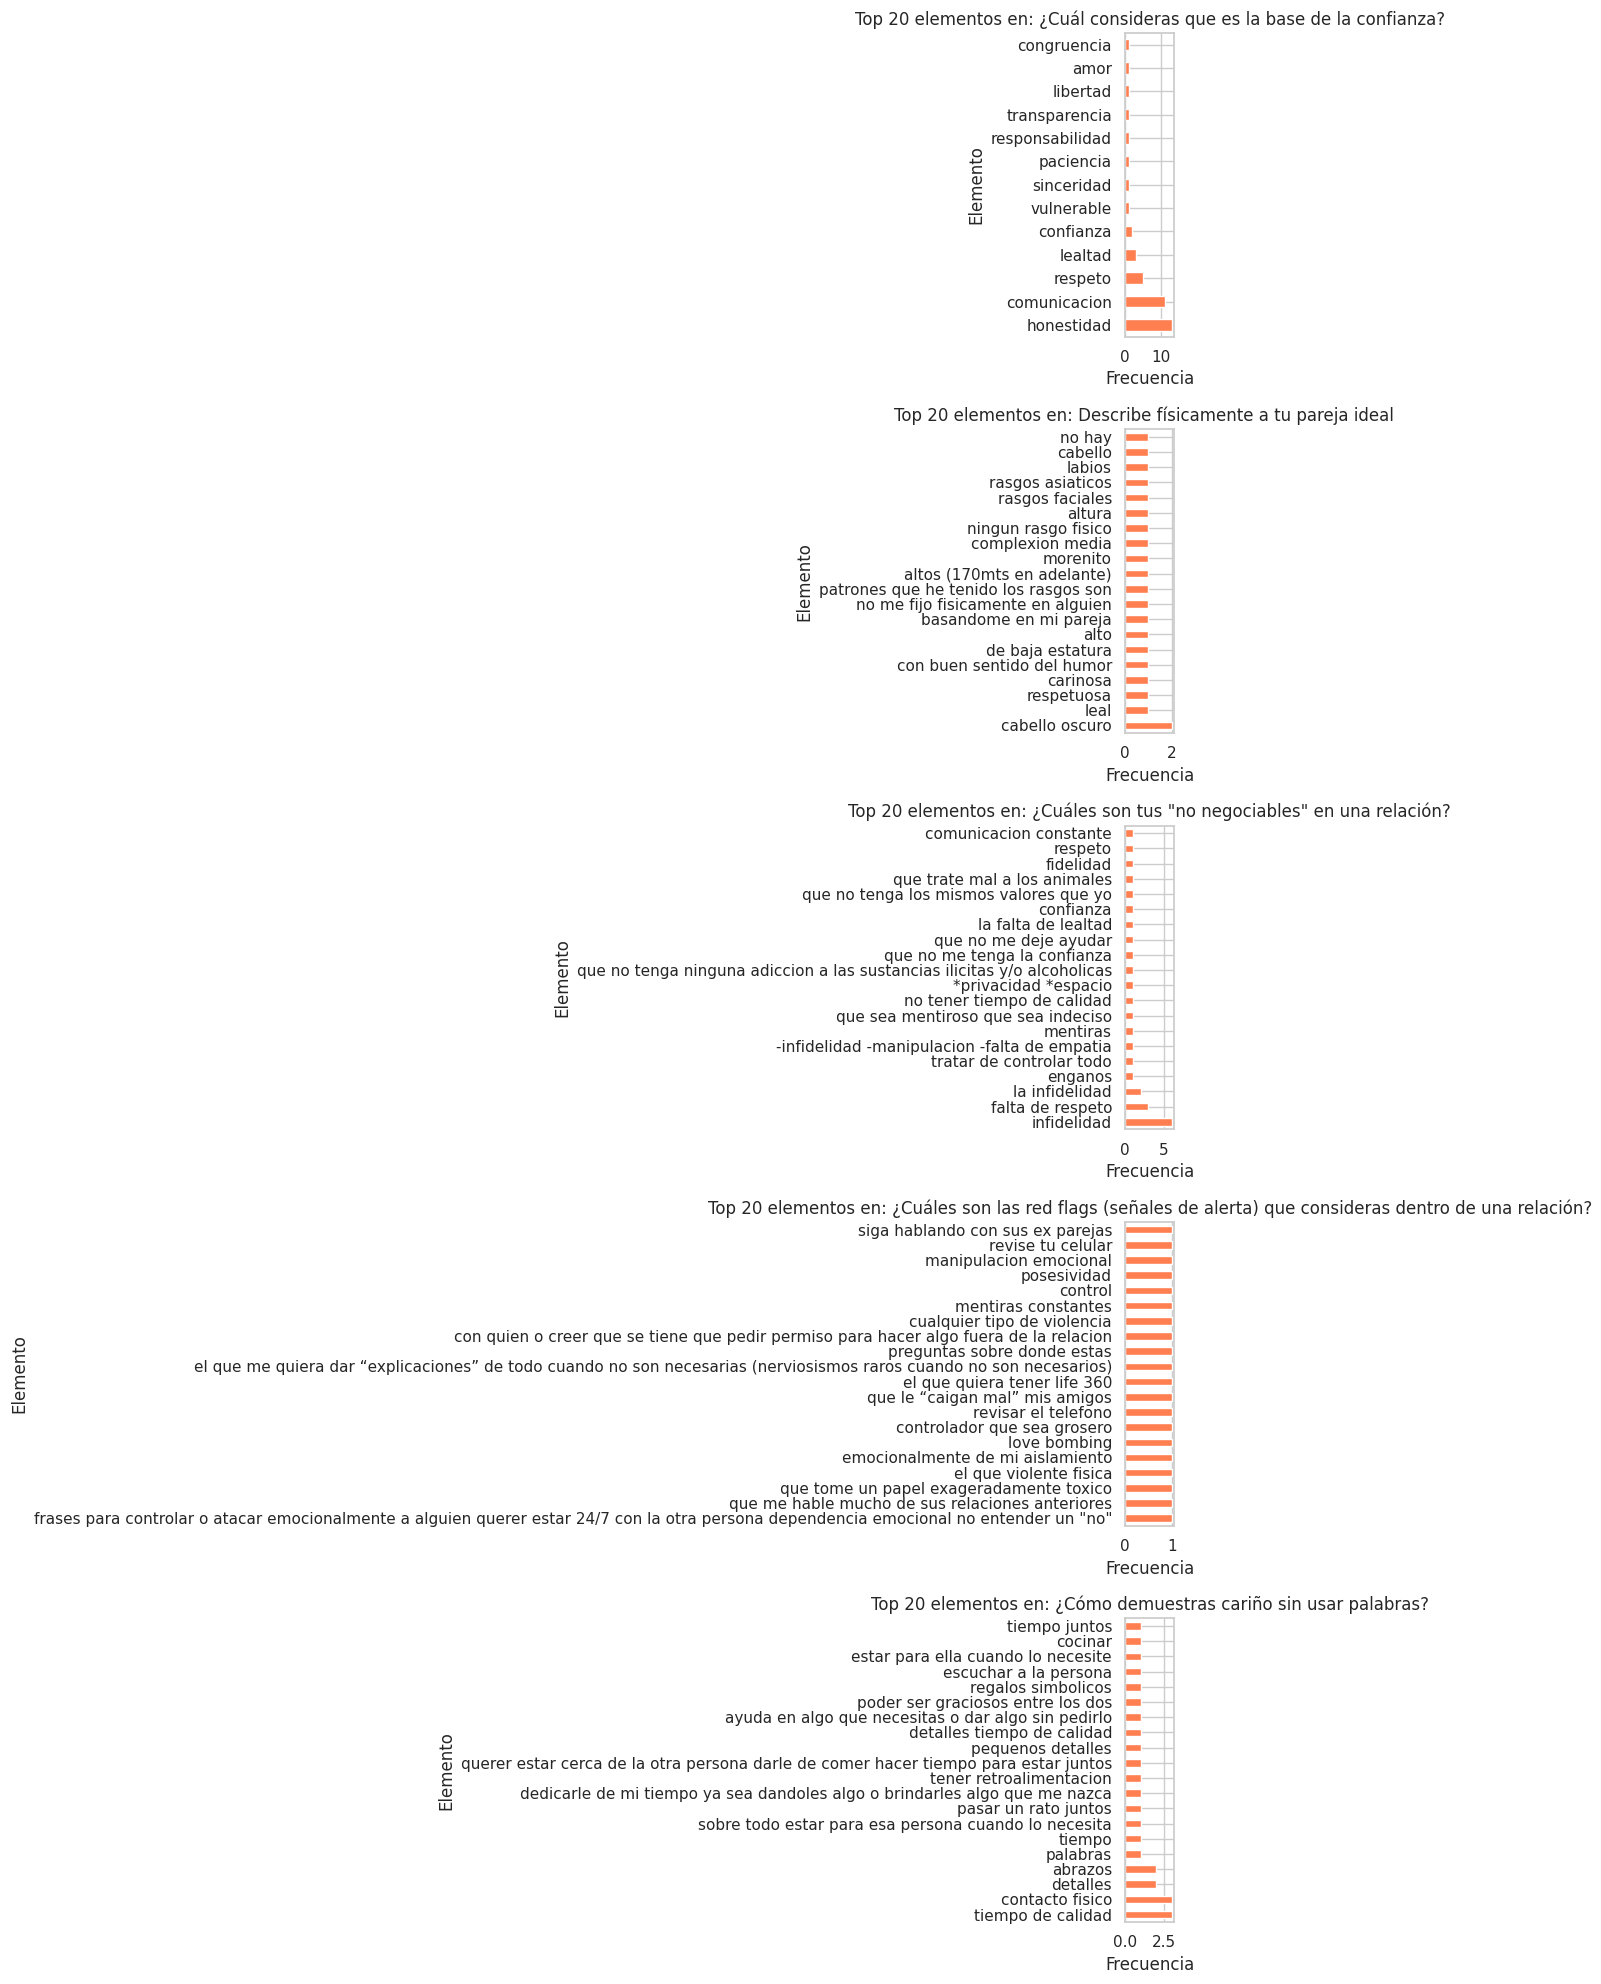

In [21]:
fig, axes = plt.subplots(len(cols_listas), 1, figsize=(12, 4 * len(cols_listas)))

if len(cols_listas) == 1:
    axes = [axes]

for i, col in enumerate(cols_listas):
    ax = axes[i]

    # Separar por comas, explotar y contar
    palabras = df[col].dropna().str.split(', ').explode()
    conteo = palabras.value_counts().head(20)  # Top 20

    if len(conteo) > 0:
        conteo.plot(kind='barh', ax=ax, color='coral')
        ax.set_title(f'Top 20 elementos en: {col}')
        ax.set_xlabel('Frecuencia')
        ax.set_ylabel('Elemento')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f'{col}')

plt.tight_layout()
plt.show()

## 5. Exportar datos limpios

In [22]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_CSV, index=False)
print(f"✓ Datos limpios guardados en: {PROCESSED_CSV}")
print(f"  Filas: {len(df)}")
print(f"  Columnas: {len(df.columns)}")

NameError: name 'PROCESSED_DIR' is not defined